# Predicting Crime Severity in LA with Crime Attributes

Members: Carmel Norris (group leader), Alicia Ellis, Sayhan Khan, Lindsey Duffner, Navaj Sivakumar

#### Goal: 
Predict crime severity (part 1 (serious) or part 2 (not very serious)) from various crime attributes (where, when, premise type, weapon, etc.) using Los Angeles Crime Data from 2020 to 2023.

[Link to Dataset](https://www.kaggle.com/datasets/asaniczka/crimes-in-los-angeles-2020-2023?resource=download)

## Exploring the Data

In [1]:
import pandas as pd

df = pd.read_csv('Crime_Data_from_2020_to_Present.csv')

display(df.head())

,division_number,date_reported,date_occurred,area,area_name,reporting_district,part,crime_code,crime_description,modus_operandi,...,status,status_description,crime_code_1,crime_code_2,crime_code_3,crime_code_4,location,cross_street,latitude,longitude
0,10304468,2020-01-08,2020-01-08 22:30:00,3,Southwest,377,2,624,BATTERY - SIMPLE ASSAULT,0444 0913,...,AO,Adult Other,624.0,NaN,NaN,NaN,1100 W 39TH PL,NaN,34.0141,-118.2978
1,190101086,2020-01-02,2020-01-01 03:30:00,1,Central,163,2,624,BATTERY - SIMPLE ASSAULT,0416 1822 1414,...,IC,Invest Cont,624.0,NaN,NaN,NaN,700 S HILL ST,NaN,34.0459,-118.2545
2,200110444,2020-04-14,2020-02-13 12:00:00,1,Central,155,2,845,SEX OFFENDER REGISTRANT OUT OF COMPLIANCE,1501,...,AA,Adult Arrest,845.0,NaN,NaN,NaN,200 E 6TH ST,NaN,34.0448,-118.2474
3,191501505,2020-01-01,2020-01-01 17:30:00,15,N Hollywood,1543,2,745,VANDALISM - MISDEAMEANOR ($399 OR UNDER),0329 1402,...,IC,Invest Cont,745.0,998.0,NaN,NaN,5400 CORTEEN PL,NaN,34.1685,-118.4019
4,191921269,2020-01-01,2020-01-01 04:15:00,19,Mission,1998,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329,...,IC,Invest Cont,740.0,NaN,NaN,NaN,14400 TITUS ST,NaN,34.2198,-118.4468


In [2]:
df.shape

(852950, 27)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 852950 entries, 0 to 852949
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   division_number      852950 non-null  int64  
 1   date_reported        852950 non-null  str    
 2   date_occurred        852950 non-null  str    
 3   area                 852950 non-null  int64  
 4   area_name            852950 non-null  str    
 5   reporting_district   852950 non-null  int64  
 6   part                 852950 non-null  int64  
 7   crime_code           852950 non-null  int64  
 8   crime_description    852950 non-null  str    
 9   modus_operandi       734639 non-null  str    
 10  victim_age           852950 non-null  int64  
 11  victim_sex           740344 non-null  str    
 12  victim_descent       740336 non-null  str    
 13  premise_code         852940 non-null  float64
 14  premise_description  852432 non-null  str    
 15  weapon_code          296748 

In [4]:
df.isnull().sum()

division_number             0
date_reported               0
date_occurred               0
area                        0
area_name                   0
reporting_district          0
part                        0
crime_code                  0
crime_description           0
modus_operandi         118311
victim_age                  0
victim_sex             112606
victim_descent         112614
premise_code               10
premise_description       518
weapon_code            556202
weapon_description     556202
status                      0
status_description          0
crime_code_1               11
crime_code_2           790429
crime_code_3           850837
crime_code_4           852888
location                    0
cross_street           717289
latitude                    0
longitude                   0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,division_number,area,reporting_district,part,crime_code,victim_age,premise_code,weapon_code,crime_code_1,crime_code_2,crime_code_3,crime_code_4,latitude,longitude
count,8.529500e+05,852950.000000,852950.000000,852950.000000,852950.000000,852950.000000,852940.000000,296748.000000,852939.000000,62521.000000,2113.000000,62.000000,852950.000000,852950.000000
mean,2.166969e+08,10.707354,1117.165490,1.412575,500.746338,29.742191,305.974292,363.225141,500.486350,957.630028,983.847137,990.983871,33.983232,-118.040106
std,1.100081e+07,6.097178,609.716073,0.492298,207.705242,21.799470,216.950442,123.685519,207.493864,111.237318,52.526227,27.477259,1.756263,6.089068
min,8.170000e+02,1.000000,101.000000,1.000000,110.000000,-3.000000,101.000000,101.000000,110.000000,210.000000,310.000000,821.000000,0.000000,-118.667600
25%,2.102184e+08,6.000000,615.000000,1.000000,331.000000,5.000000,101.000000,310.000000,331.000000,998.000000,998.000000,998.000000,34.014100,-118.429700
50%,2.202184e+08,11.000000,1141.000000,1.000000,442.000000,31.000000,203.000000,400.000000,442.000000,998.000000,998.000000,998.000000,34.058500,-118.321500
75%,2.301094e+08,16.000000,1617.000000,2.000000,626.000000,45.000000,501.000000,400.000000,626.000000,998.000000,998.000000,998.000000,34.163200,-118.273900
max,2.399306e+08,21.000000,2199.000000,2.000000,956.000000,120.000000,976.000000,516.000000,956.000000,999.000000,999.000000,999.000000,34.334300,0.000000


In [7]:
leak_cols = ['crime_code', 'crime_description', 'modus_operandi', 'crime_code_1', 'crime_code_2', 'crime_code_3', 'crime_code_4']
df = df.drop(columns=leak_cols)

In [8]:
irrel_cols = ['division_number', 'location', 'cross_street']
df = df.drop(columns=irrel_cols)

In [9]:
dup_cols = ['date_reported', 'area', 'premise_code', 'weapon_code', 'status']
df = df.drop(columns=dup_cols)

print(df.shape)
print(df.isnull().sum())

(852950, 12)
date_occurred               0
area_name                   0
reporting_district          0
part                        0
victim_age                  0
victim_sex             112606
victim_descent         112614
premise_description       518
weapon_description     556202
status_description          0
latitude                    0
longitude                   0
dtype: int64


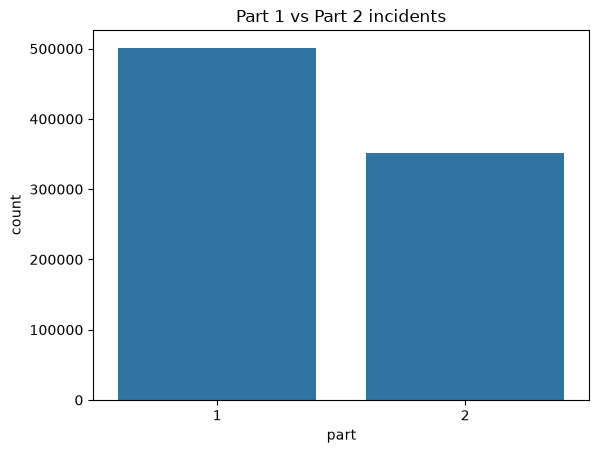

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# class imbalance
sns.countplot(data=df, x='part')
plt.title("Part 1 vs Part 2 incidents")
plt.show()


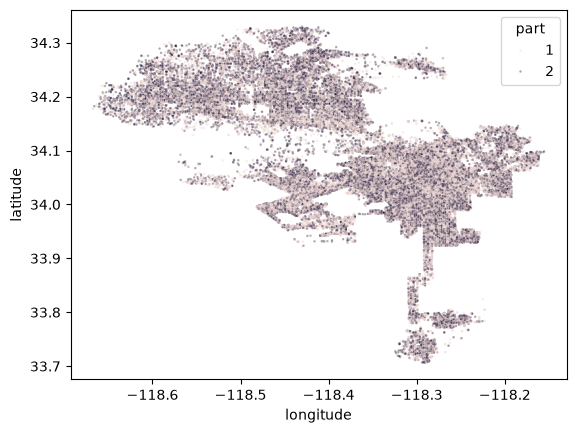

In [11]:
# map showing crime location
s = df.sample(100_000, random_state=42).copy()

g = s[s["latitude"] != 0]
sns.scatterplot(data=g, x="longitude", y="latitude", hue="part", s=3, alpha=0.4)
plt.show()

In [12]:
d = pd.to_datetime(df["date_occurred"])
df["hour"], df["dayofweek"], df["month"] = d.dt.hour, d.dt.dayofweek, d.dt.month

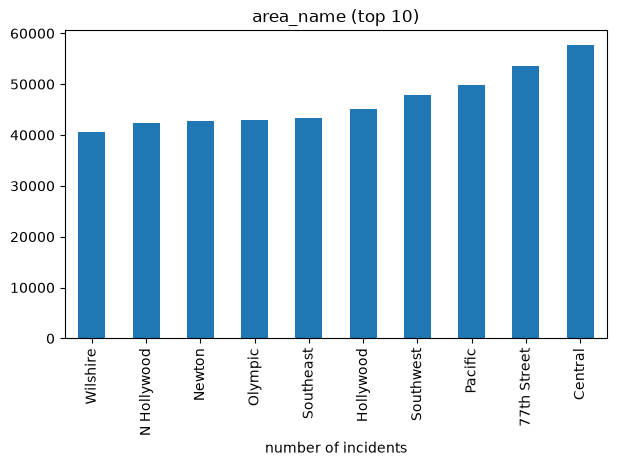

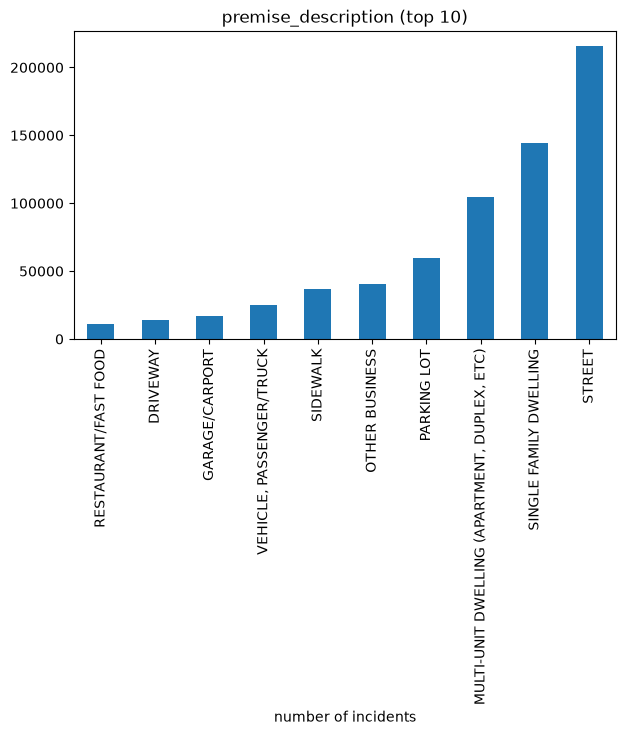

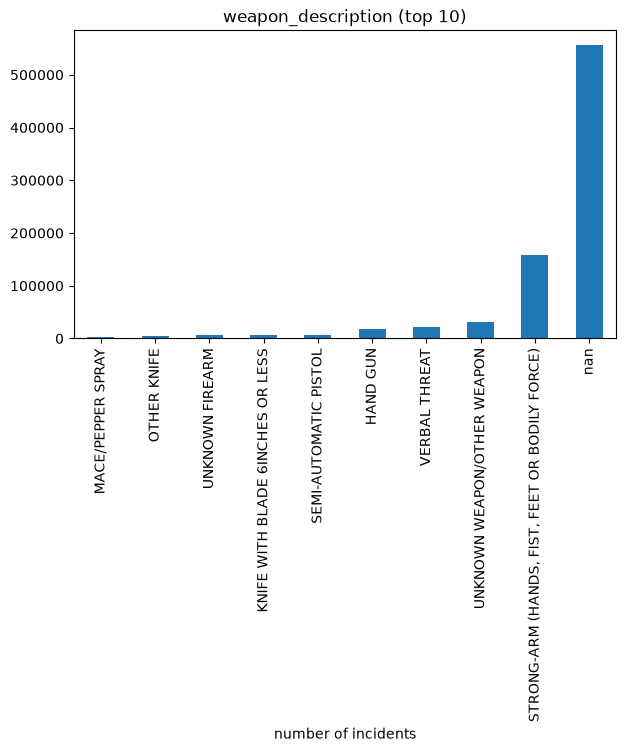

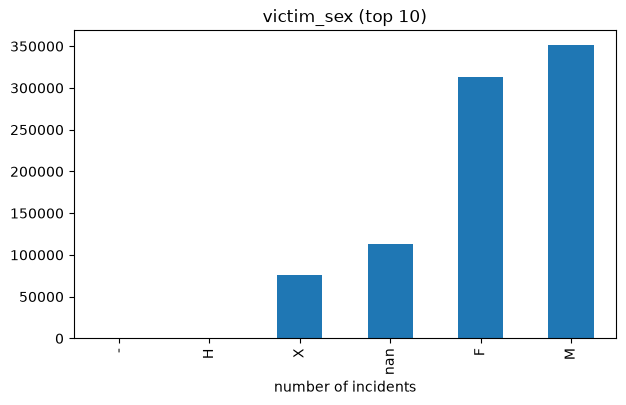

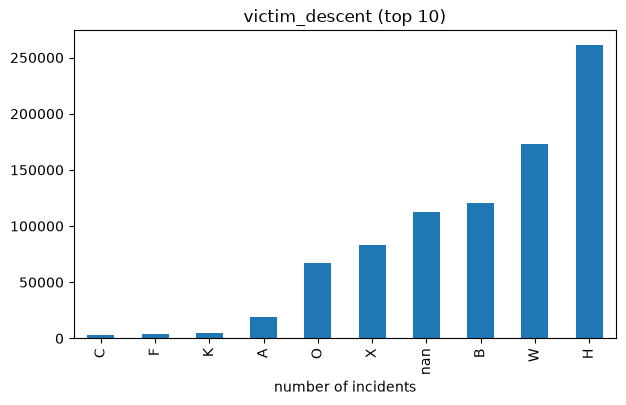

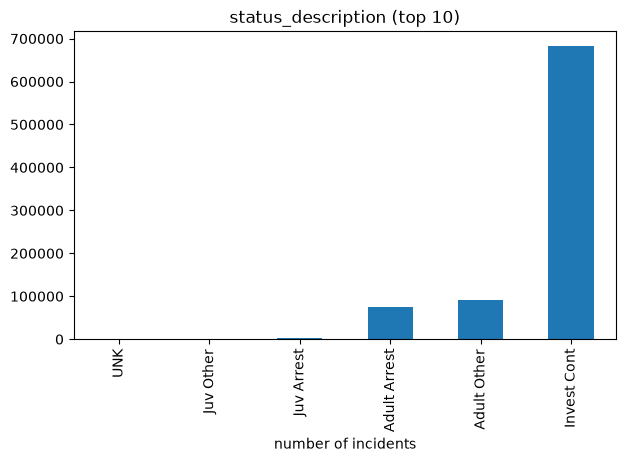

In [13]:
def bar(col, top=10):
    df[col].value_counts(dropna=False).head(top).sort_values().plot(
        kind="bar", figsize=(7, 4), title=f"{col} (top {top})")
    plt.xlabel("number of incidents")
    plt.show()

for c in ["area_name", "premise_description", "weapon_description",
          "victim_sex", "victim_descent", "status_description"]:
    bar(c)

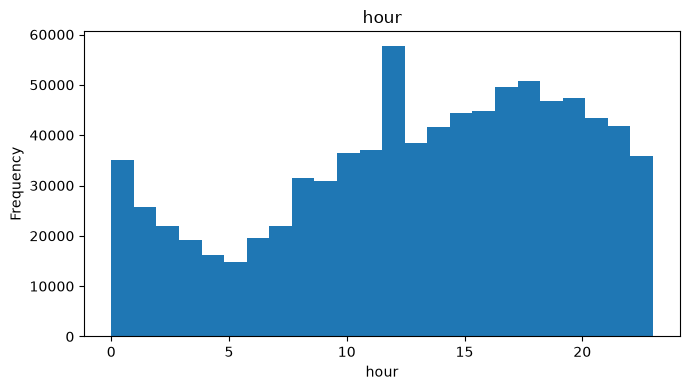

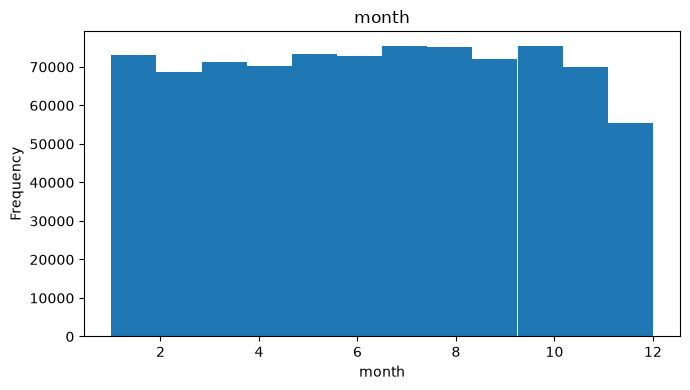

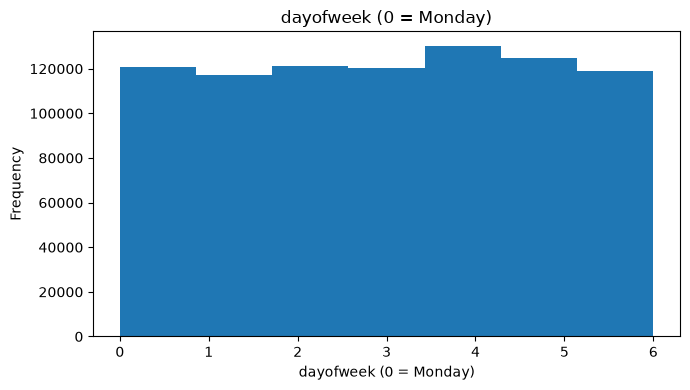

In [14]:
def hist(series, title, bins=30):
    series.plot(kind="hist", bins=bins, figsize=(7, 4), title=title)
    plt.xlabel(title)
    plt.tight_layout()
    plt.show()
    
hist(df["hour"], "hour", bins=24)
hist(df["month"], "month", bins=12)
hist(df["dayofweek"], "dayofweek (0 = Monday)", bins=7)

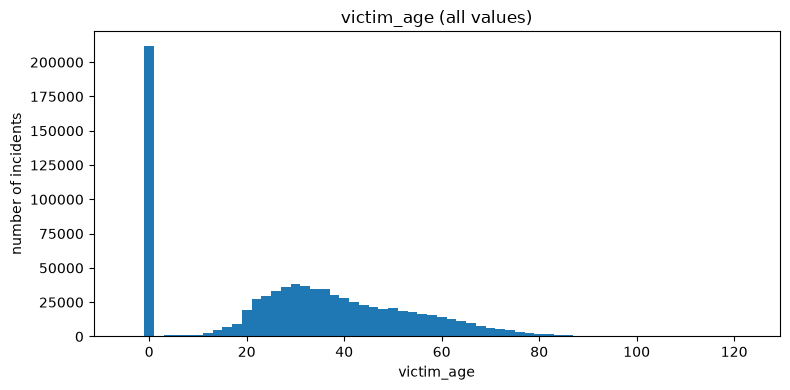

In [15]:
df["victim_age"].plot(kind="hist", bins=range(-5, 125, 2), figsize=(8, 4),
                      title="victim_age (all values)")
plt.xlabel("victim_age")
plt.ylabel("number of incidents")
plt.tight_layout()
plt.show()

Rough Plan: 
- handle nulls and outliers
- encode categorical variables
- make correlation heat map
- balance classes with SMOTE
- models: logistic regression, decision tree, K-nearest neighbor, random forest, gradient boosting, stacking 